In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

zip_name = next(
    name for name in uploaded
    if name.endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/cyber_traffic_data")

DATA_DIR = "/content/cyber_traffic_data"

print("Files extracted successfully!")
print(os.listdir(DATA_DIR))

Saving cyber_traffic_sample_data.zip to cyber_traffic_sample_data.zip
Files extracted successfully!
['calendar.csv', 'flows.csv', 'README_Data_Quality.txt', 'sessions.csv', 'labels.csv', 'hosts.csv']


In [ ]:
flows = pd.read_csv(f"{DATA_DIR}/flows.csv")
hosts = pd.read_csv(f"{DATA_DIR}/hosts.csv")
sessions = pd.read_csv(f"{DATA_DIR}/sessions.csv")
labels = pd.read_csv(f"{DATA_DIR}/labels.csv")
calendar = pd.read_csv(f"{DATA_DIR}/calendar.csv")
datasets = {
    "flows": flows,
    "hosts": hosts,
    "sessions": sessions,
    "labels": labels,
    "calendar": calendar
}
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


--- FLOWS ---
Shape: (20, 9)
Columns: ['Flow_ID', 'Timestamp', 'Source_Host_ID', 'Destination_Host_ID', 'Protocol', 'Bytes', 'Packets', 'Duration_ms', 'Source_Host_Group']


,Flow_ID,Timestamp,Source_Host_ID,Destination_Host_ID,Protocol,Bytes,Packets,Duration_ms,Source_Host_Group
0,F001,2026-09-01 08:07:00,H001,H006,UDP,420,4,12,Engineering
1,F002,2026-09-01 11:14:00,H002,H007,HTTPS,1800,12,35,HR
2,F003,2026-09-01 14:21:00,H003,H008,DNS,760,7,9,Operations



--- HOSTS ---
Shape: (20, 5)
Columns: ['Host_ID', 'Host_Name', 'Host_Group', 'Zone', 'OS_Type']


,Host_ID,Host_Name,Host_Group,Zone,OS_Type
0,H001,host-01,Engineering,Internal,Linux
1,H002,host-02,HR,Internal,Windows
2,H003,host-03,Operations,DMZ,Linux



--- SESSIONS ---
Shape: (20, 10)
Columns: ['Session_ID', 'Flow_ID', 'Source_Host_ID', 'Destination_Host_ID', 'Source_Zone', 'Destination_Zone', 'Source_Port', 'Destination_Port', 'Host_Group', 'Connection_Status']


,Session_ID,Flow_ID,Source_Host_ID,Destination_Host_ID,Source_Zone,Destination_Zone,Source_Port,Destination_Port,Host_Group,Connection_Status
0,S001,F001,H001,H007,Internal,External,443,51514,Engineering,Closed
1,S002,F002,H002,H008,DMZ,Internal,53,53001,HR,Reset
2,S003,F003,H003,H009,External,Internal,22,49220,Operations,Timed_Out



--- LABELS ---
Shape: (20, 5)
Columns: ['Label_ID', 'Flow_ID', 'Event_Label', 'Label_Source', 'Confidence']


,Label_ID,Flow_ID,Event_Label,Label_Source,Confidence
0,L001,F001,Normal,Rule_Based,0.98
1,L002,F002,normal,Analyst_Review,0.82
2,L003,F003,NORMAL,Rule_Based,0.91



--- CALENDAR ---
Shape: (20, 5)
Columns: ['Date', 'Day_of_Week', 'Is_Weekend', 'Is_Holiday', 'Business_Period']


,Date,Day_of_Week,Is_Weekend,Is_Holiday,Business_Period
0,2026-09-01,Tuesday,No,No,Month_Start
1,2026-09-02,Wednesday,No,No,Month_Start
2,2026-09-03,Thursday,No,No,Month_Start


In [ ]:
#Inspect data types and summary statistics
for name, df in datasets.items():
    print(f"\n--- {name.upper()} INFO ---")
    df.info()

print("\nNumeric summary of network flows:")
display(flows.describe())


--- FLOWS INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Flow_ID              20 non-null     object
 1   Timestamp            20 non-null     object
 2   Source_Host_ID       20 non-null     object
 3   Destination_Host_ID  20 non-null     object
 4   Protocol             18 non-null     object
 5   Bytes                20 non-null     int64 
 6   Packets              20 non-null     int64 
 7   Duration_ms          20 non-null     int64 
 8   Source_Host_Group    20 non-null     object
dtypes: int64(3), object(6)
memory usage: 1.5+ KB

--- HOSTS INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Host_ID     20 non-null     object
 1   Host_Name   20 non-null     object
 2   Ho

,Bytes,Packets,Duration_ms
count,2.000000e+01,20.000000,20.00000
mean,1.377336e+06,13.600000,60.00000
std,4.450365e+06,9.505677,66.30075
min,4.200000e+02,4.000000,9.00000
25%,8.425000e+02,7.000000,16.00000
50%,1.800000e+03,10.500000,28.50000
75%,2.650000e+03,18.000000,80.00000
max,1.800000e+07,36.000000,210.00000


In [ ]:
#check missing values
for name, df in datasets.items():
    print(f"\n--- Missing values in {name} ---")
    missing = df.isnull().sum()
    print(missing[missing > 0] if missing.any() else "No missing values detected")


--- Missing values in flows ---
Protocol    2
dtype: int64

--- Missing values in hosts ---
No missing values detected

--- Missing values in sessions ---
No missing values detected

--- Missing values in labels ---
No missing values detected

--- Missing values in calendar ---
No missing values detected


In [ ]:
#delete duplicated flow ids
print("Total flow records:", len(flows))
print("Unique flow IDs:", flows["Flow_ID"].nunique())
print("Duplicate flow ID rows:",
      flows["Flow_ID"].duplicated(keep=False).sum())

duplicate_flows = flows[
    flows["Flow_ID"].duplicated(keep=False)
].sort_values("Flow_ID")

display(duplicate_flows)

Total flow records: 20
Unique flow IDs: 19
Duplicate flow ID rows: 2


,Flow_ID,Timestamp,Source_Host_ID,Destination_Host_ID,Protocol,Bytes,Packets,Duration_ms,Source_Host_Group
4,F005,2026-09-01 20:35:00,H005,H010,TCP,980,9,22,Finance
19,F005,2026-09-03 17:20:00,H020,H005,TCP,870,8,19,Finance


In [ ]:
#Inspect inconsistent labels
print("Original event labels:")
display(labels["Event_Label"].value_counts(dropna=False).to_frame())

print("\nDistinct labels:")
print(sorted(labels["Event_Label"].dropna().unique()))

Original event labels:


,count
Event_Label,
Normal,5
Suspicious,3
normal,2
Malicious,2
NORMAL,1
Suspicios,1
suspicious,1
MALICIOUS,1
Benign,1



Distinct labels:
['Benign', 'MALICIOUS', 'Malicious', 'Malicous', 'NORMAL', 'Normal', 'SUSPICIOUS', 'Suspicios', 'Suspicious', 'benign', 'normal', 'suspicious']


In [ ]:
#Detect extreme byte counts using the IQR method
Q1 = flows["Bytes"].quantile(0.25)
Q3 = flows["Bytes"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = flows[
    (flows["Bytes"] < lower_bound) |
    (flows["Bytes"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outlier records:", len(outliers))

display(outliers[["Flow_ID", "Timestamp", "Bytes", "Protocol"]])

Q1: 842.5
Q3: 2650.0
IQR: 1807.5
Lower bound: -1868.75
Upper bound: 5361.25
Potential outlier records: 4


,Flow_ID,Timestamp,Bytes,Protocol
5,F006,2026-09-01 23:42:00,12000,UDP
7,F008,2026-09-02 05:56:00,9500000,DNS
15,F016,2026-09-03 05:52:00,12000,UDP
16,F017,2026-09-03 08:59:00,18000000,HTTPS


In [ ]:
#Detect unmatched host groups
known_groups = set(hosts["Host_Group"].dropna().str.strip())
flow_groups = set(flows["Source_Host_Group"].dropna().str.strip())
session_groups = set(sessions["Host_Group"].dropna().str.strip())

print("Unmatched groups in flows.csv:")
print(sorted(flow_groups - known_groups))

print("\nUnmatched groups in sessions.csv:")
print(sorted(session_groups - known_groups))

Unmatched groups in flows.csv:
['Legacy_Group', 'Unmapped_Team']

Unmatched groups in sessions.csv:
['Legacy_Group', 'Unmapped_Team']


In [ ]:
#Clean labels and prepare analysis tables
# Create copies so the original data remains unchanged
flows_clean = flows.copy()
hosts_clean = hosts.copy()
sessions_clean = sessions.copy()
labels_clean = labels.copy()
calendar_clean = calendar.copy()

# Standardize whitespace and capitalization
for df, columns in [
    (flows_clean, ["Protocol", "Source_Host_Group"]),
    (hosts_clean, ["Host_Group", "Zone", "OS_Type"]),
    (sessions_clean, ["Host_Group", "Source_Zone",
                      "Destination_Zone", "Connection_Status"]),
    (labels_clean, ["Event_Label", "Label_Source"])
]:
    for col in columns:
        df[col] = df[col].astype("string").str.strip()

# Normalize known label variations using an explicit mapping
label_mapping = {
    "normal": "Normal",
    "benign": "Normal",
    "suspicious": "Suspicious",
    "suspicios": "Suspicious",
    "malicious": "Malicious",
    "malicous": "Malicious"
}

labels_clean["Event_Label"] = (
    labels_clean["Event_Label"]
    .str.lower()
    .map(label_mapping)
    .fillna("Unknown")
)

# Normalize protocol casing but preserve missing values
flows_clean["Protocol"] = flows_clean["Protocol"].str.upper()

# Parse date/time
flows_clean["Timestamp"] = pd.to_datetime(
    flows_clean["Timestamp"], errors="coerce"
)
calendar_clean["Date"] = pd.to_datetime(
    calendar_clean["Date"], errors="coerce"
)

# Fill missing protocols with an explicit placeholder for grouping
flows_clean["Protocol"] = flows_clean["Protocol"].fillna("Unknown")

# Remove duplicate Flow_ID records for this analysis only.
# Keep the first record and retain the original flows DataFrame unchanged.
flows_unique = flows_clean.drop_duplicates(
    subset="Flow_ID", keep="first"
).copy()

print("Original flow rows:", len(flows))
print("Flow rows after deduplication:", len(flows_unique))
print("\nStandardized labels:")
display(labels_clean["Event_Label"].value_counts().to_frame())

Original flow rows: 20
Flow rows after deduplication: 19

Standardized labels:


,count
Event_Label,
Normal,10
Suspicious,6
Malicious,4


In [ ]:
#Create additional features
flows_unique["Date"] = flows_unique["Timestamp"].dt.normalize()
flows_unique["Hour"] = flows_unique["Timestamp"].dt.hour
flows_unique["Day_of_Week"] = flows_unique["Timestamp"].dt.day_name()

# Calculate the average bytes per packet
flows_unique["Bytes_Per_Packet"] = (
    flows_unique["Bytes"] /
    flows_unique["Packets"].replace(0, np.nan)
)

# Create a flag for extreme byte counts using the IQR rule
Q1 = flows_unique["Bytes"].quantile(0.25)
Q3 = flows_unique["Bytes"].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

flows_unique["High_Byte_Flag"] = (
    flows_unique["Bytes"] > upper_bound
)

print("New features created:")
display(flows_unique[
    ["Flow_ID", "Date", "Hour", "Day_of_Week",
     "Bytes_Per_Packet", "High_Byte_Flag"]
].head())

New features created:


,Flow_ID,Date,Hour,Day_of_Week,Bytes_Per_Packet,High_Byte_Flag
0,F001,2026-09-01,8,Tuesday,105.000000,False
1,F002,2026-09-01,11,Tuesday,150.000000,False
2,F003,2026-09-01,14,Tuesday,108.571429,False
3,F004,2026-09-01,17,Tuesday,133.333333,False
4,F005,2026-09-01,20,Tuesday,108.888889,False


Flows matched to labels: 19
Flows without matching labels: 0
Labels without matching flows: 1


,Protocol,Flow_Count
0,UDP,2
1,HTTPS,2
2,DNS,2
3,TCP,2
4,Unknown,1
5,SSH,1


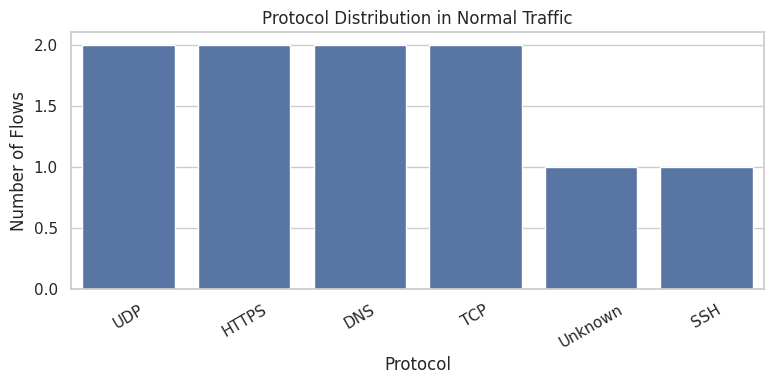

In [ ]:
#Analyse normal traffic protocols
flow_label_data = flows_unique.merge(
    labels_clean[["Flow_ID", "Event_Label"]],
    on="Flow_ID",
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Flows matched to labels:",
      (flow_label_data["_merge"] == "both").sum())
print("Flows without matching labels:",
      (flow_label_data["_merge"] == "left_only").sum())
print("Labels without matching flows:",
      (~labels_clean["Flow_ID"].isin(flows_unique["Flow_ID"])).sum())

normal_data = flow_label_data[
    flow_label_data["Event_Label"] == "Normal"
]

protocol_counts = (
    normal_data["Protocol"]
    .value_counts()
    .rename_axis("Protocol")
    .reset_index(name="Flow_Count")
)

display(protocol_counts)

if not protocol_counts.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(
        data=protocol_counts,
        x="Protocol",
        y="Flow_Count"
    )
    plt.title("Protocol Distribution in Normal Traffic")
    plt.xlabel("Protocol")
    plt.ylabel("Number of Flows")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [ ]:
#Which features differ across event categories?
feature_data = flow_label_data[
    flow_label_data["Event_Label"].isin(
        ["Normal", "Suspicious", "Malicious"]
    )
].copy()

feature_columns = ["Bytes", "Packets", "Duration_ms"]

summary = (
    feature_data.groupby("Event_Label")[feature_columns]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

display(summary)

Bytes                         Packets                 \
                  mean  median   min       max    mean median min max   
Event_Label                                                             
Malicious    4504125.0  7200.0  2100  18000000    18.5   16.5   5  36   
Normal          1216.0   815.0   420      3400     9.3    7.5   4  22   
Suspicious   1903436.0  2400.0   980   9500000    19.4   18.0   9  36   

            Duration_ms                  
                   mean median min  max  
Event_Label                              
Malicious         88.25   63.5  16  210  
Normal            33.10   17.5   9  150  
Suspicious        99.40   80.0  22  210

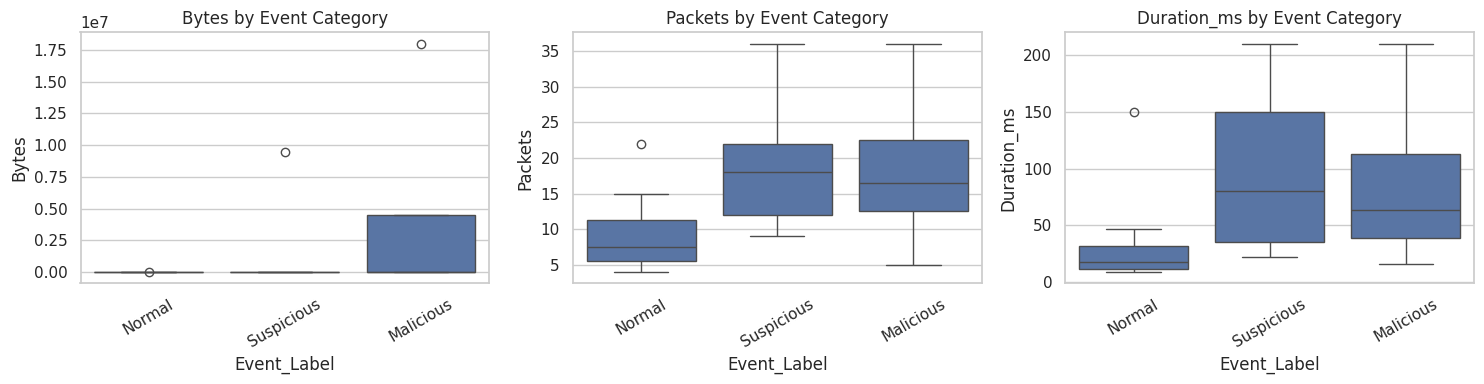

In [ ]:
#Visualize feature differences
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, feature_columns):
    sns.boxplot(
        data=feature_data,
        x="Event_Label",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Event Category")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
#analyse traffic by hour
hourly_traffic = (
    flows_unique.groupby("Hour")
    .agg(
        Flow_Count=("Flow_ID", "count"),
        Total_Bytes=("Bytes", "sum"),
        Average_Bytes=("Bytes", "mean")
    )
    .reset_index()
    .sort_values("Hour")
)

display(hourly_traffic)

,Hour,Flow_Count,Total_Bytes,Average_Bytes
0,2,2,1630,8.150000e+02
1,5,2,9512000,4.756000e+06
2,8,3,18002520,6.000840e+06
3,11,3,6070,2.023333e+03
4,14,3,3280,1.093333e+03
5,17,2,4200,2.100000e+03
6,20,2,1740,8.700000e+02
7,23,2,14400,7.200000e+03


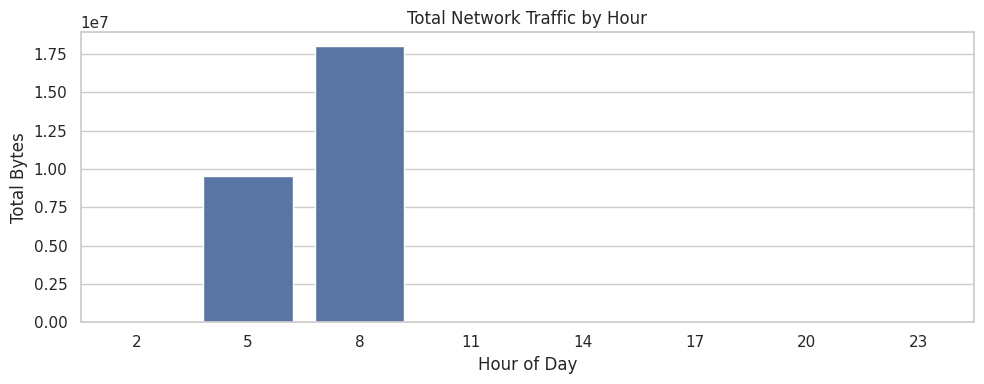

In [ ]:
#Plot traffic volume by hour
plt.figure(figsize=(10, 4))
sns.barplot(
    data=hourly_traffic,
    x="Hour",
    y="Total_Bytes"
)
plt.title("Total Network Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Bytes")
plt.tight_layout()
plt.show()

In [ ]:
# hours show unusual volume
Q1_hour = hourly_traffic["Total_Bytes"].quantile(0.25)
Q3_hour = hourly_traffic["Total_Bytes"].quantile(0.75)
IQR_hour = Q3_hour - Q1_hour
hour_threshold = Q3_hour + 1.5 * IQR_hour
unusual_hours = hourly_traffic[
    hourly_traffic["Total_Bytes"] > hour_threshold
]

print("Hourly traffic threshold:", hour_threshold)
print("Potential unusual hours:")
display(unusual_hours)

Hourly traffic threshold: 5967657.5
Potential unusual hours:


,Hour,Flow_Count,Total_Bytes,Average_Bytes
1,5,2,9512000,4756000.0
2,8,3,18002520,6000840.0


In [ ]:
#Merge session and flow information
zone_data = sessions_clean.merge(
    flows_unique[
        ["Flow_ID", "Bytes", "Packets", "Duration_ms", "Protocol"]
    ],
    on="Flow_ID",
    how="left",
    indicator=True,
    validate="many_to_one"
)

print("Session rows:", len(sessions_clean))
print("Sessions matched to flow data:",
      (zone_data["_merge"] == "both").sum())
print("Sessions without matching flows:",
      (zone_data["_merge"] == "left_only").sum())

display(zone_data.head())

Session rows: 20
Sessions matched to flow data: 19
Sessions without matching flows: 1


,Session_ID,Flow_ID,Source_Host_ID,Destination_Host_ID,Source_Zone,Destination_Zone,Source_Port,Destination_Port,Host_Group,Connection_Status,Bytes,Packets,Duration_ms,Protocol,_merge
0,S001,F001,H001,H007,Internal,External,443,51514,Engineering,Closed,420.0,4.0,12.0,UDP,both
1,S002,F002,H002,H008,DMZ,Internal,53,53001,HR,Reset,1800.0,12.0,35.0,HTTPS,both
2,S003,F003,H003,H009,External,Internal,22,49220,Operations,Timed_Out,760.0,7.0,9.0,DNS,both
3,S004,F004,H004,H010,Internal,DMZ,80,60412,Guest,Established,2400.0,18.0,80.0,Unknown,both
4,S005,F005,H005,H011,Internal,External,3389,49880,Finance,Closed,980.0,9.0,22.0,TCP,both


In [ ]:
#Classify traffic direction
def classify_direction(row):
    source = row["Source_Zone"]
    destination = row["Destination_Zone"]

    if pd.isna(source) or pd.isna(destination):
        return "Unknown"

    if source == "Internal" and destination == "Internal":
        return "Internal-to-Internal"

    if source == "Internal" and destination != "Internal":
        return "Internal-to-Non-Internal"

    if source != "Internal" and destination == "Internal":
        return "Non-Internal-to-Internal"

    return "Non-Internal-to-Non-Internal"

zone_data["Traffic_Direction"] = zone_data.apply(
    classify_direction, axis=1
)

display(zone_data["Traffic_Direction"].value_counts().to_frame())

,count
Traffic_Direction,
Internal-to-Non-Internal,10
Non-Internal-to-Internal,10


,Traffic_Direction,Session_Count,Total_Bytes,Average_Bytes,Average_Duration_ms
0,Internal-to-Non-Internal,10,27520460.0,3057828.89,64.56
1,Non-Internal-to-Internal,10,25380.0,2538.00,60.00


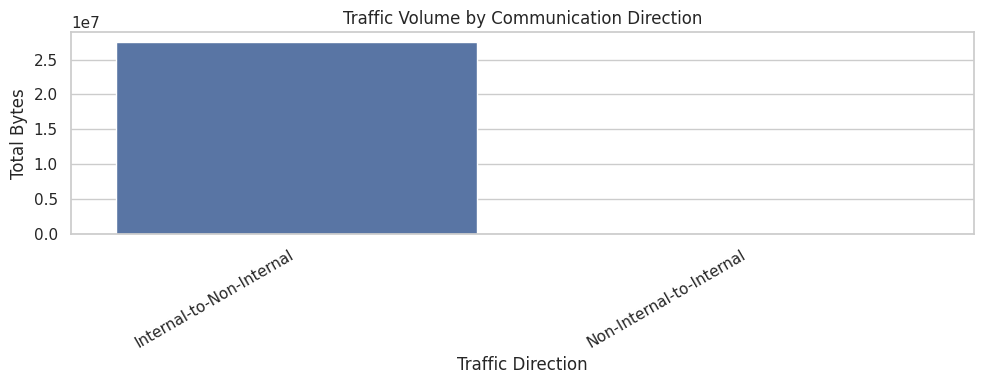

In [ ]:
#Compare traffic volume by direction
direction_summary = (
    zone_data.groupby("Traffic_Direction")
    .agg(
        Session_Count=("Session_ID", "count"),
        Total_Bytes=("Bytes", "sum"),
        Average_Bytes=("Bytes", "mean"),
        Average_Duration_ms=("Duration_ms", "mean")
    )
    .round(2)
    .reset_index()
)

display(direction_summary)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=direction_summary,
    x="Traffic_Direction",
    y="Total_Bytes"
)
plt.title("Traffic Volume by Communication Direction")
plt.xlabel("Traffic Direction")
plt.ylabel("Total Bytes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Count source and destination ports
source_ports = (
    sessions_clean["Source_Port"]
    .value_counts()
    .rename_axis("Port")
    .reset_index(name="Count")
)
source_ports["Port_Type"] = "Source"

destination_ports = (
    sessions_clean["Destination_Port"]
    .value_counts()
    .rename_axis("Port")
    .reset_index(name="Count")
)
destination_ports["Port_Type"] = "Destination"

port_counts = pd.concat(
    [source_ports, destination_ports],
    ignore_index=True
)

display(port_counts.sort_values("Count", ascending=False))

,Port,Count,Port_Type
12,49880,4,Destination
9,53001,4,Destination
10,49220,4,Destination
11,60412,4,Destination
8,51514,4,Destination
0,443,3,Source
3,80,3,Source
2,22,3,Source
1,53,3,Source
4,3389,2,Source


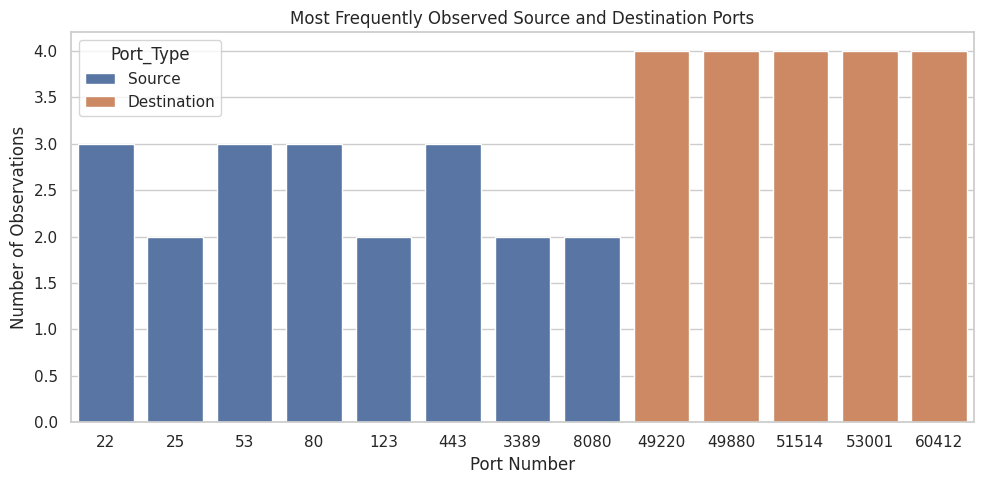

In [ ]:
#Visualize the most frequent ports
top_ports = port_counts.sort_values(
    "Count", ascending=False
).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_ports,
    x="Port",
    y="Count",
    hue="Port_Type"
)
plt.title("Most Frequently Observed Source and Destination Ports")
plt.xlabel("Port Number")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [ ]:
#Inspect less common ports
print("Source port frequencies:")
display(source_ports.sort_values("Count", ascending=False))

print("Destination port frequencies:")
display(destination_ports.sort_values("Count", ascending=False))

print("Ports observed only once:")
display(
    port_counts[port_counts["Count"] == 1]
    .sort_values(["Port_Type", "Port"])
)

Source port frequencies:


,Port,Count,Port_Type
0,443,3,Source
1,53,3,Source
2,22,3,Source
3,80,3,Source
4,3389,2,Source
5,8080,2,Source
6,25,2,Source
7,123,2,Source


Destination port frequencies:


,Port,Count,Port_Type
0,51514,4,Destination
1,53001,4,Destination
2,49220,4,Destination
3,60412,4,Destination
4,49880,4,Destination


Ports observed only once:


,Port,Count,Port_Type


In [ ]:
#Join flow groups with event labels
alert_data = flows_unique[
    ["Flow_ID", "Source_Host_Group", "Bytes", "Protocol"]
].merge(
    labels_clean[["Flow_ID", "Event_Label"]],
    on="Flow_ID",
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Rows in alert analysis:", len(alert_data))
print("Unmatched flow records:",
      (alert_data["_merge"] == "left_only").sum())

display(alert_data.head())

Rows in alert analysis: 19
Unmatched flow records: 0


,Flow_ID,Source_Host_Group,Bytes,Protocol,Event_Label,_merge
0,F001,Engineering,420,UDP,Normal,both
1,F002,HR,1800,HTTPS,Normal,both
2,F003,Operations,760,DNS,Normal,both
3,F004,Guest,2400,Unknown,Suspicious,both
4,F005,Finance,980,TCP,Suspicious,both


In [ ]:
#Count alerts by host group
alert_labels = ["Suspicious", "Malicious"]

alerts = alert_data[
    alert_data["Event_Label"].isin(alert_labels)
].copy()

alert_summary = (
    alerts.groupby("Source_Host_Group")
    .agg(
        Alert_Count=("Flow_ID", "count"),
        Unique_Flow_Count=("Flow_ID", "nunique"),
        Total_Bytes=("Bytes", "sum")
    )
    .reset_index()
    .sort_values("Alert_Count", ascending=False)
)

display(alert_summary)

,Source_Host_Group,Alert_Count,Unique_Flow_Count,Total_Bytes
2,Guest,3,3,6900
3,HR,2,2,18001800
1,Finance,1,1,980
0,Engineering,1,1,12000
4,Operations,1,1,9500000
5,Unmapped_Team,1,1,12000


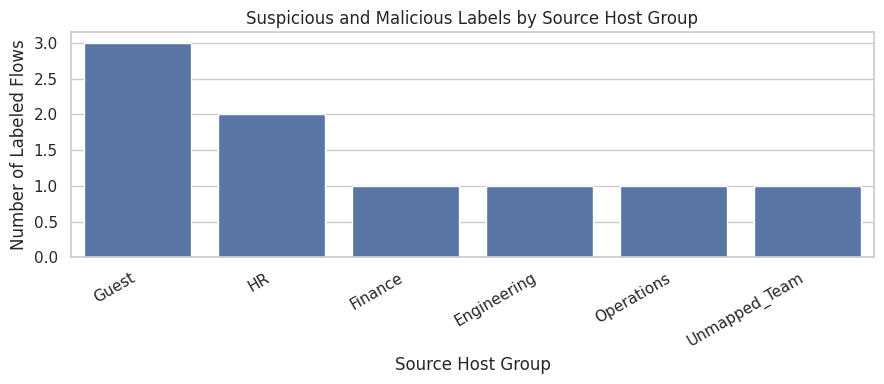

In [ ]:
#Plot alert counts
if not alert_summary.empty:
    plt.figure(figsize=(9, 4))
    sns.barplot(
        data=alert_summary,
        x="Source_Host_Group",
        y="Alert_Count"
    )
    plt.title("Suspicious and Malicious Labels by Source Host Group")
    plt.xlabel("Source Host Group")
    plt.ylabel("Number of Labeled Flows")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No matching alert labels found.")

In [ ]:
#Inspect unmatched groups separately
unmatched_alert_groups = alert_summary[
    ~alert_summary["Source_Host_Group"].isin(known_groups)
]

print("Groups that do not exist in hosts.csv:")
display(unmatched_alert_groups)

Groups that do not exist in hosts.csv:


,Source_Host_Group,Alert_Count,Unique_Flow_Count,Total_Bytes
5,Unmapped_Team,1,1,12000


In [ ]:
#Generate a data-quality summary
quality_report = pd.DataFrame({
    "Check": [
        "Total flow records",
        "Unique flow IDs",
        "Missing protocol values",
        "Duplicate flow ID rows",
        "Extreme byte-count records",
        "Unmatched source host groups",
        "Labels without matching flow IDs"
    ],
    "Result": [
        len(flows),
        flows["Flow_ID"].nunique(),
        flows["Protocol"].isna().sum(),
        flows["Flow_ID"].duplicated(keep=False).sum(),
        (flows["Bytes"] > 1_000_000).sum(),
        len(flow_groups - known_groups),
        (~labels_clean["Flow_ID"].isin(flows_clean["Flow_ID"])).sum()
    ]
})

display(quality_report)

,Check,Result
0,Total flow records,20
1,Unique flow IDs,19
2,Missing protocol values,2
3,Duplicate flow ID rows,2
4,Extreme byte-count records,2
5,Unmatched source host groups,2
6,Labels without matching flow IDs,1


In [ ]:
#Export your analysis tables
output_dir = "/content/round2_results"
os.makedirs(output_dir, exist_ok=True)

quality_report.to_csv(
    f"{output_dir}/data_quality_report.csv", index=False
)
protocol_counts.to_csv(
    f"{output_dir}/port_protocol_analysis.csv", index=False
)
hourly_traffic.to_csv(
    f"{output_dir}/hourly_traffic_analysis.csv", index=False
)
direction_summary.to_csv(
    f"{output_dir}/traffic_direction_analysis.csv", index=False
)
alert_summary.to_csv(
    f"{output_dir}/host_group_alert_analysis.csv", index=False
)

print("Round 2 analysis tables saved successfully.")

# Download the results folder as a ZIP
import shutil
shutil.make_archive(
    "/content/round2_results",
    "zip",
    output_dir
)

files.download("/content/round2_results.zip")

Round 2 analysis tables saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>